# Does the first antenatal visit add predictive value?

**Incremental Predictive Value of Two Antenatal Visits for Recorded Low Birth Weight: A Retrospective Cohort Study.** Kelvin Rwihimba, BSc Software Engineering, African Leadership University. Supervisor: Emmanuel Adjei.

**The question.** When a pregnancy is seen for the second time, at or before 28 weeks, does information from the first visit help predict a recorded birth weight below 2.5 kg beyond what the second visit already shows?

**How to read this notebook.** It explains the analysis and shows its results. It does not compute them. Every table and figure below was written by `python -m antenatal run-analysis`, which runs the tested code in `src/antenatal`. Every sentence that states a result is printed by code from those tables, so the words cannot drift from the numbers. If the outputs are missing, the first cell runs the analysis, which takes a few minutes.

**What is not here.** The held out partition, 20 percent of the cohort sealed before any modelling step, is not read anywhere in this notebook. It is evaluated once, separately, after the supervisor has reviewed the analysis plan.

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, display

from antenatal.config import PRIMARY
from antenatal.features.screen import ScreenResult
from antenatal.features.sets import LINEAR, PRIMARY_SETS, TREE, SetC
from antenatal.models.factory import MODEL_SPECS
from antenatal.paths import ProjectPaths

paths = ProjectPaths.from_root(Path.cwd().parent)
if not (paths.outputs / "oof_predictions.parquet").exists():
    from antenatal.analysis import run_analysis
    run_analysis(paths.ensure())

pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
table = lambda name: pd.read_csv(paths.tables / f"{name}.csv")
figure = lambda name: display(Image(filename=str(paths.figures / f"{name}.png")))
manifest = json.loads((paths.outputs / "manifest.json").read_text())
print("Data SHA 256:", manifest["inputs"]["data"]["sha256"])
print("Seed:", manifest["seed"], "| scikit-learn", manifest["environment"]["scikit-learn"])

Data SHA 256: ab95366ef22dde5d13df93f10723942f5faffda8fbf0007e8efe85e4f25c1126
Seed: 20260930 | scikit-learn 1.8.0


## 1. The plan, fixed before any result

| Element | Decision |
| --- | --- |
| Outcome | Recorded birth weight below 2.5 kg |
| Prediction point | The second antenatal visit, at or before 28 weeks, later than the first |
| Set A | Registration characteristics only |
| Set B | Set A plus the second visit measurements |
| Set C | Set B plus the first visit value of each measurement recorded at both visits for at least 60 percent of development records |
| Primary test | Set C against set B on the area under the precision recall curve |
| Secondary test | Set B against set A on the area under the ROC curve |
| Validation | Five outer folds, repeated ten times, grouped by registration profile; tuning inside three inner folds |
| Interval | Group bootstrap of the paired difference, 2,000 resamples, on predictions averaged per pregnancy |
| Imbalance | No class weighting and no resampling, so probabilities stay on the natural scale |

**Why precision recall is the main score.** Low birth weight is rare here, so a model that never predicts it is right about 95 percent of the time. The area under the precision recall curve rewards placing the rare cases near the top of the ranking, and a model with no skill scores the prevalence. Every value below should be read against that floor.

Analysis cohort: 3,908 pregnancies, 206 events
Development partition used here: 3,126 pregnancies, 165 events (5.28 percent)


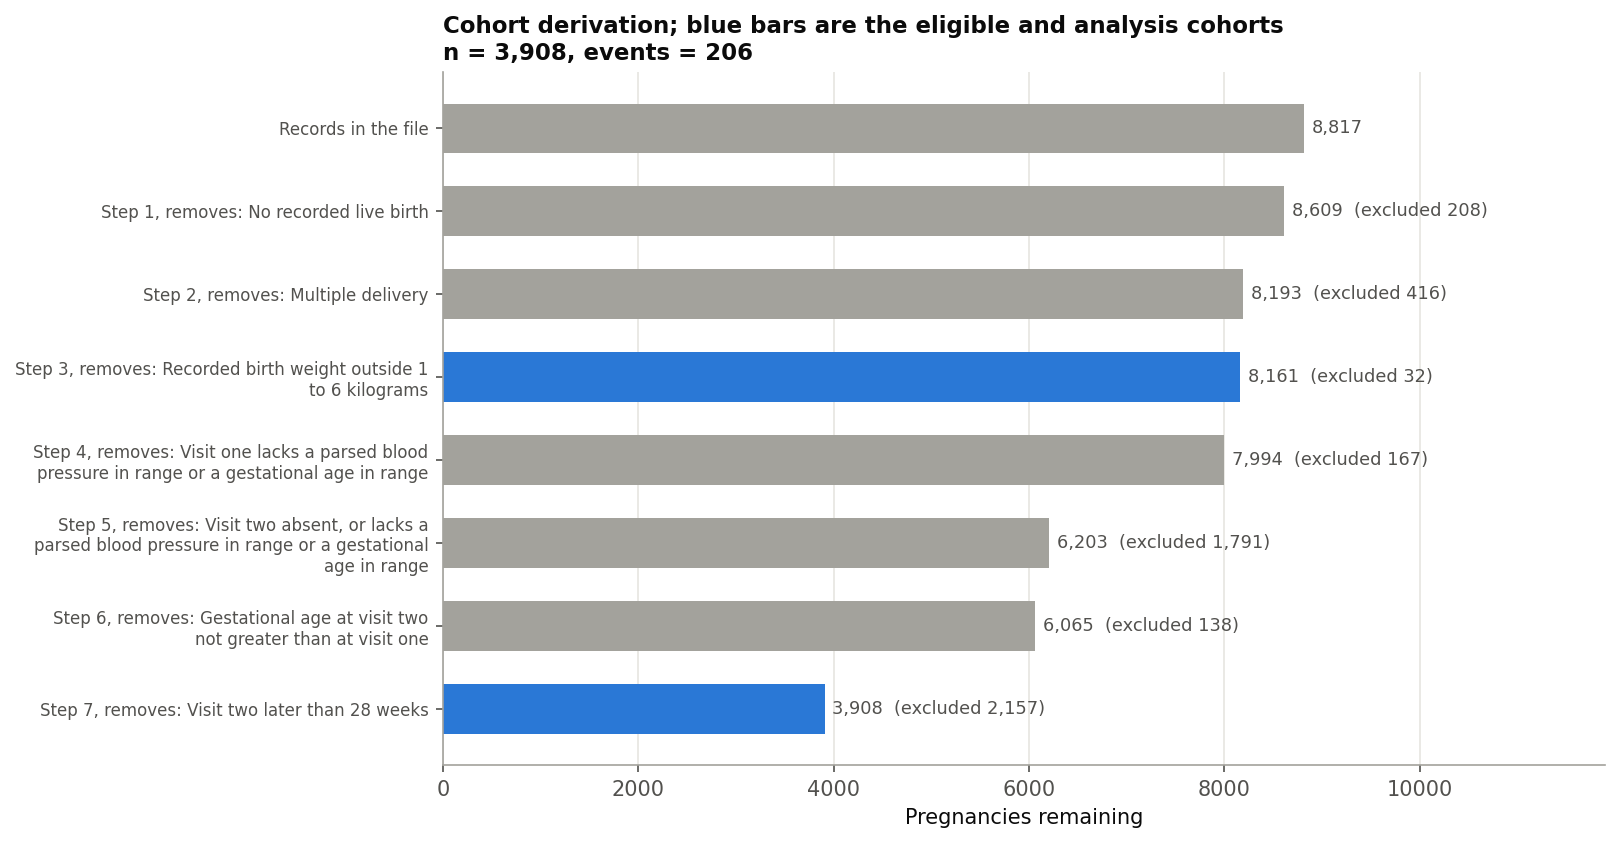

In [2]:
flow = table("cohort_flow")
screen = table("availability_screen")
n, events = int(screen["n_records"].iloc[0]), int(table("feature_set_comparisons")["events"].iloc[0])
print(f"Analysis cohort: {flow['remaining'].iloc[-1]:,} pregnancies, {flow['events_remaining'].iloc[-1]} events")
print(f"Development partition used here: {n:,} pregnancies, {events} events ({100 * events / n:.2f} percent)")
figure("fig01_cohort_flow")

## 2. The availability screen

A first visit measurement only enters set C if it was recorded at both visits for at least 60 percent of development records. The screen looks at availability only, never at the outcome, and inside cross validation it is refitted on each training fold.

,measurement,available_both_visits_percent,threshold_percent,result,n_records
0,sbp,100.0,60.0,pass,3126
1,dbp,100.0,60.0,pass,3126
2,weight,99.5,60.0,pass,3126
3,ga,100.0,60.0,pass,3126
4,pulse,80.6,60.0,pass,3126
5,hb,35.4,60.0,fail,3126


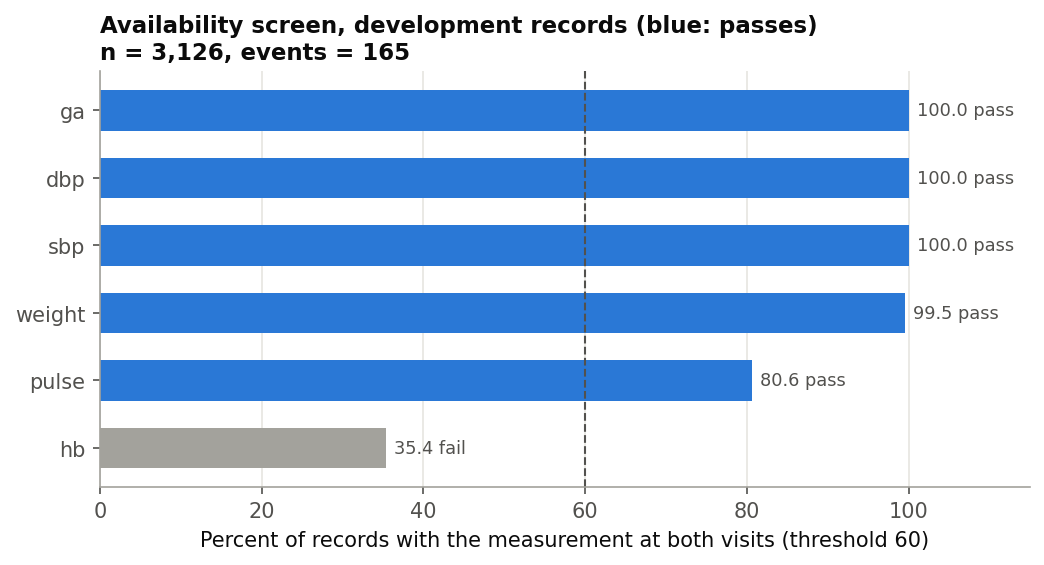

In [3]:
display(screen)
figure("fig05_availability_screen")

## 3. The feature sets

The sets are nested: everything in A is in B, and everything in B is in C, so any difference between them can only come from the added information. For a linear model the change between visits is not added, because it is the second value minus the first and the model can already form it. A tree model cannot, so it receives the change explicitly.

In [4]:
passed = screen.loc[screen["result"] == "pass"]
result = ScreenResult(dict(zip(passed["measurement"], passed["available_both_visits_percent"] / 100)), 0.6, n)
for feature_set in PRIMARY_SETS:
    print(f"Set {feature_set.name}, linear ({len(feature_set.columns(result, LINEAR))}):", ", ".join(feature_set.columns(result, LINEAR)))
print("Set C adds for trees:", ", ".join(sorted(set(SetC().columns(result, TREE)) - set(SetC().columns(result, LINEAR)))))

Set A, linear (14): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabetes, hiv, tuberculosis, sickle_cell, smoking, intimate_partner_violence
Set B, linear (20): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabetes, hiv, tuberculosis, sickle_cell, smoking, intimate_partner_violence, sbp_v2, dbp_v2, weight_v2, ga_v2, pulse_v2, hb_v2
Set C, linear (25): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabetes, hiv, tuberculosis, sickle_cell, smoking, intimate_partner_violence, sbp_v2, dbp_v2, weight_v2, ga_v2, pulse_v2, hb_v2, sbp_v1, dbp_v1, weight_v1, ga_v1, pulse_v1
Set C adds for trees: d_dbp, d_ga, d_pulse, d_sbp, d_weight


## 4. Development data at a glance

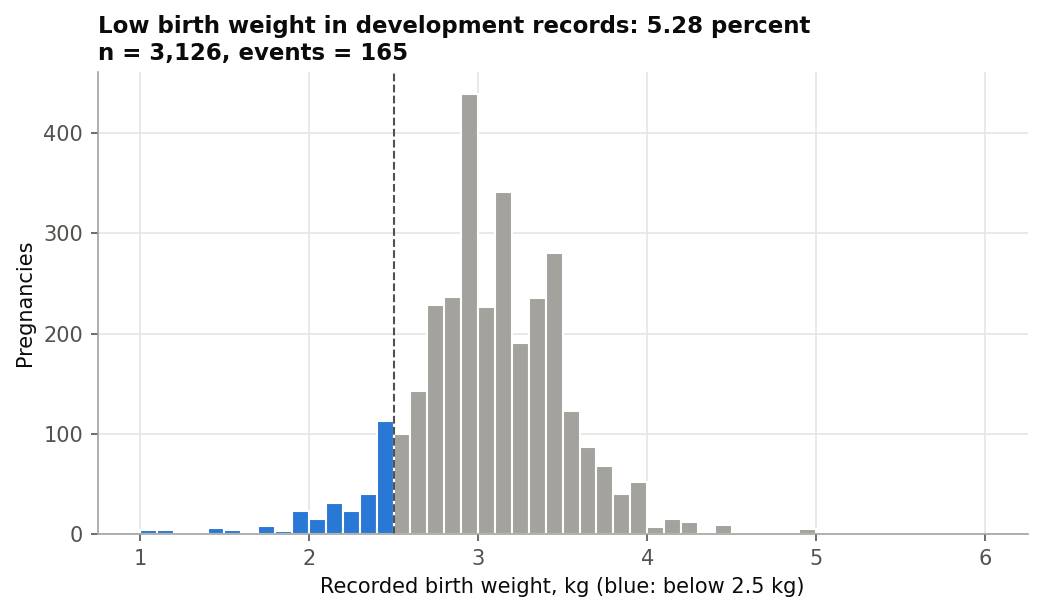

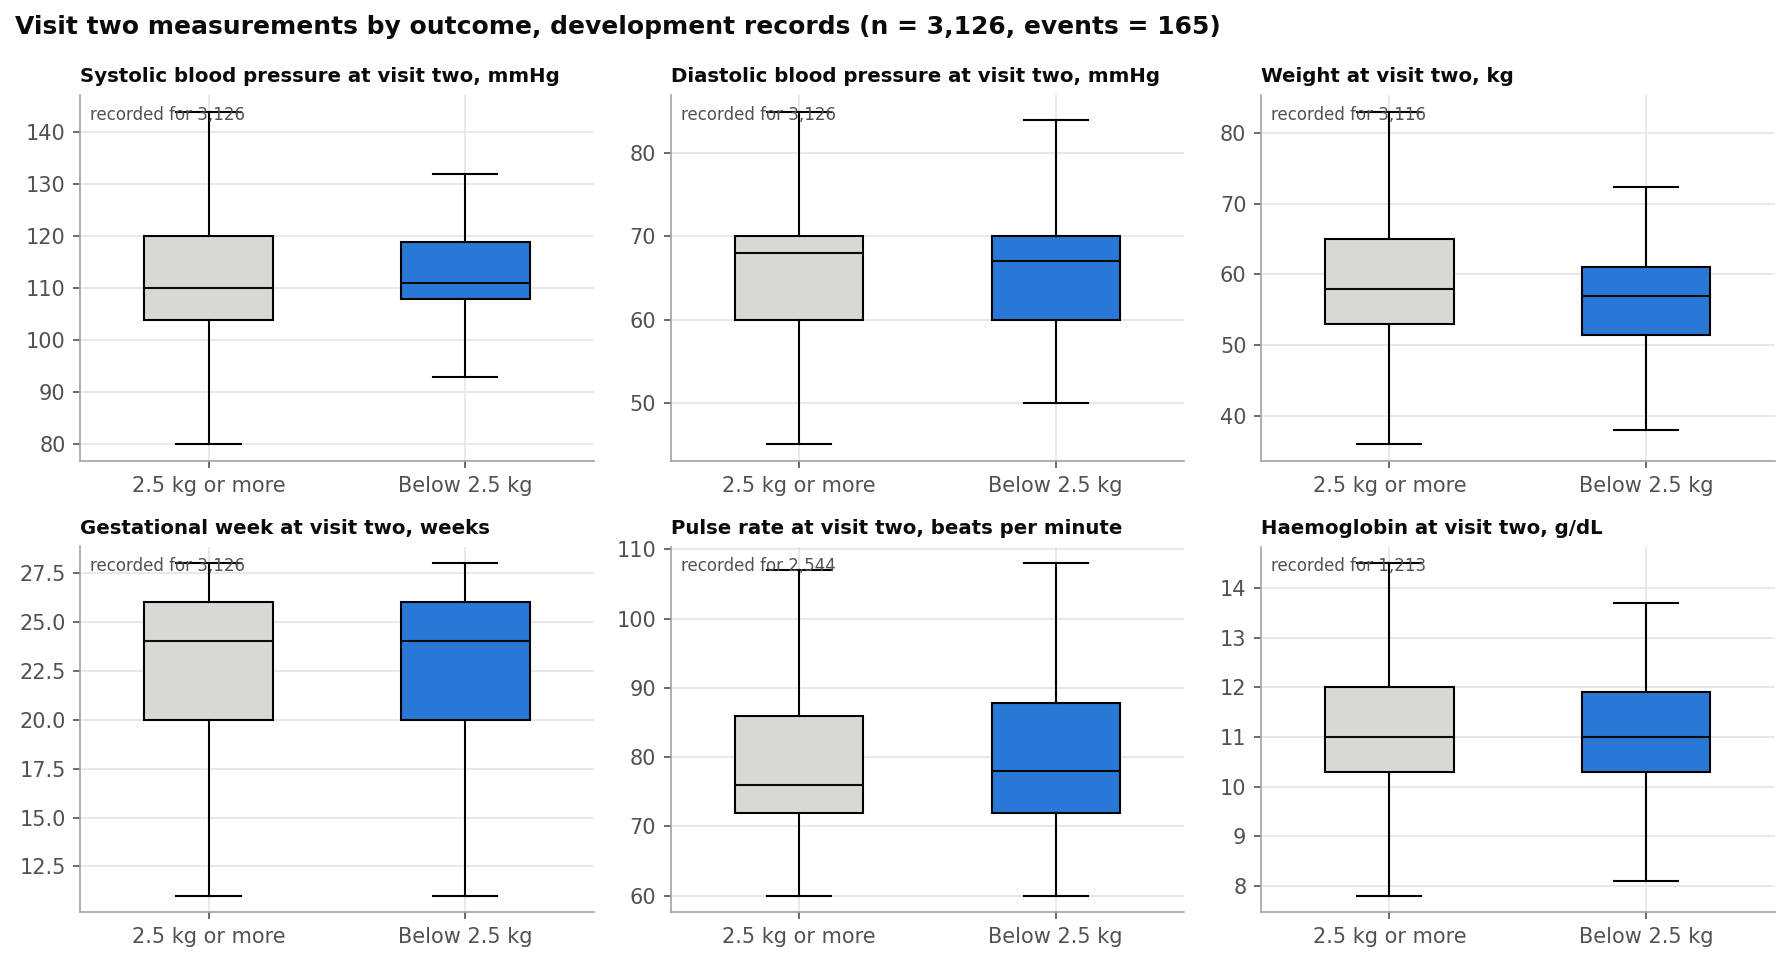

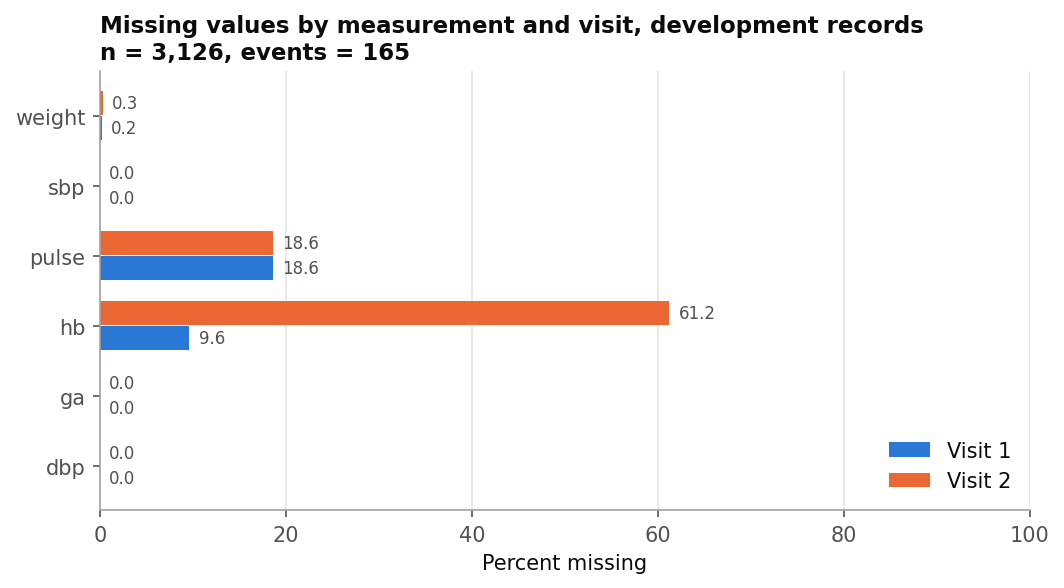

In [5]:
figure("fig02_outcome_prevalence")
figure("fig03_measurements_by_outcome")
figure("fig04_missingness")

## 5. Which model family?

Eight traditional families were fitted to set C under the same nested design (baseline B2 of the proposal), so the choice of the main model rests on evidence rather than habit. Each interval is a group bootstrap over pregnancies.

,model,value,ci_low,ci_high
30,Random forest,0.0916,0.0723,0.1233
26,"Logistic regression, L2",0.0894,0.0703,0.1178
8,Gradient boosted trees,0.0877,0.0696,0.1172
18,Linear discriminant analysis,0.0864,0.0683,0.1123
20,"Logistic regression, L1",0.0862,0.0685,0.1129
14,"GBT, uniform imputation",0.0861,0.0689,0.1119
16,Nearest neighbours,0.0730,0.0583,0.0961
2,Decision tree,0.0728,0.0598,0.0930
28,Gaussian naive Bayes,0.0693,0.0554,0.0900


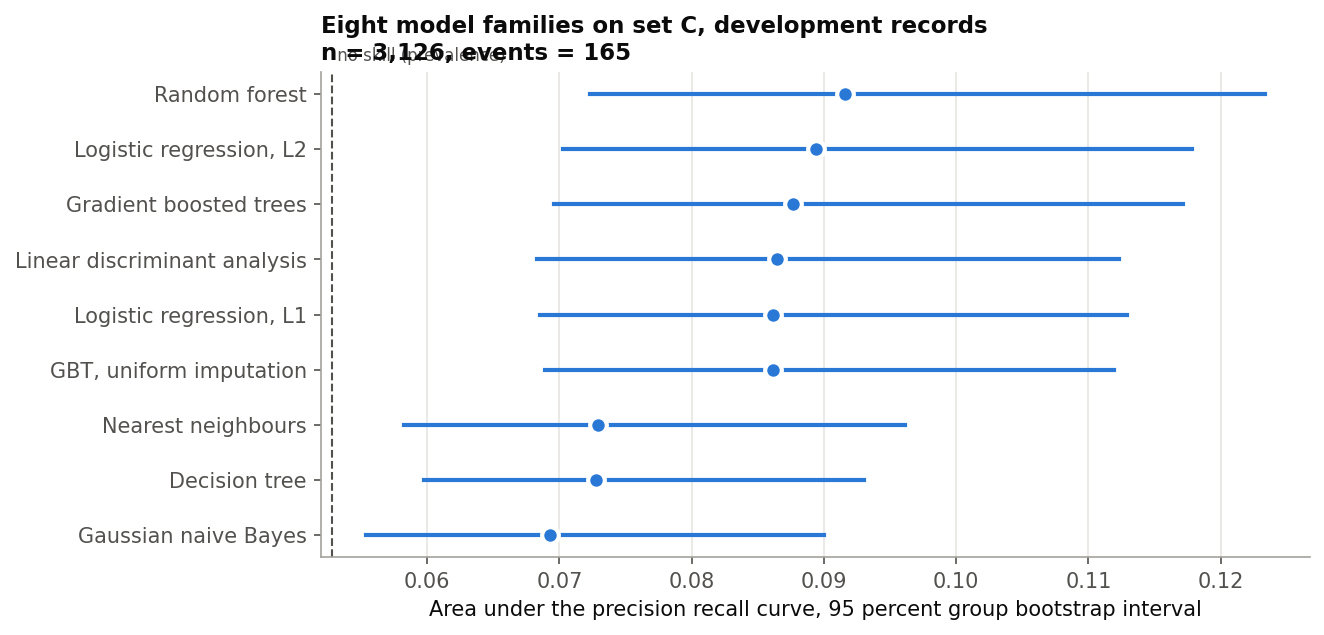

In [6]:
performance = table("model_performance")
pr = performance[(performance["metric"] == "pr_auc") & (performance["feature_set"] == "C")].copy()
pr["model"] = pr["model"].map(lambda k: MODEL_SPECS[k].label)
display(pr.sort_values("value", ascending=False)[["model", "value", "ci_low", "ci_high"]])
figure("fig06_model_families")

## 6. The answer to the research question

Each row is a paired difference: the same pregnancies, scored by the model with more information minus the model with less. If the interval includes zero, the difference cannot be told apart from sampling variation.

,model,comparison,metric,role,new_value,old_value,difference,ci_low,ci_high,detectable_difference
0,logistic_l2,C over B (first visit added),pr_auc,primary,0.0894,0.0933,-3.9599e-03,-0.0130,0.0025,0.0110
3,logistic_l2,B over A (second visit added),roc_auc,secondary,0.6318,0.6113,2.0487e-02,-0.0066,0.0476,0.0385
4,logistic_l2,C over A (both visits added),pr_auc,supporting,0.0894,0.0880,1.3560e-03,-0.0165,0.0170,0.0237
6,logistic_l2,A over B0 (registration over prevalence),pr_auc,supporting,0.0880,0.0542,3.3796e-02,0.0162,0.0625,0.0333
8,logistic_l2,B over B0,pr_auc,supporting,0.0933,0.0542,3.9112e-02,0.0205,0.0690,0.0346
10,logistic_l2,C over B0,pr_auc,supporting,0.0894,0.0542,3.5152e-02,0.0173,0.0621,0.0320
12,gradient_boosting,C over B (first visit added),pr_auc,primary,0.0877,0.0943,-6.6325e-03,-0.0173,0.0024,0.0144
15,gradient_boosting,B over A (second visit added),roc_auc,secondary,0.6538,0.6193,3.4536e-02,0.0070,0.0627,0.0397
16,gradient_boosting,C over A (both visits added),pr_auc,supporting,0.0877,0.0877,3.3639e-06,-0.0135,0.0148,0.0202
18,gradient_boosting,A over B0 (registration over prevalence),pr_auc,supporting,0.0877,0.0542,3.3449e-02,0.0161,0.0598,0.0309


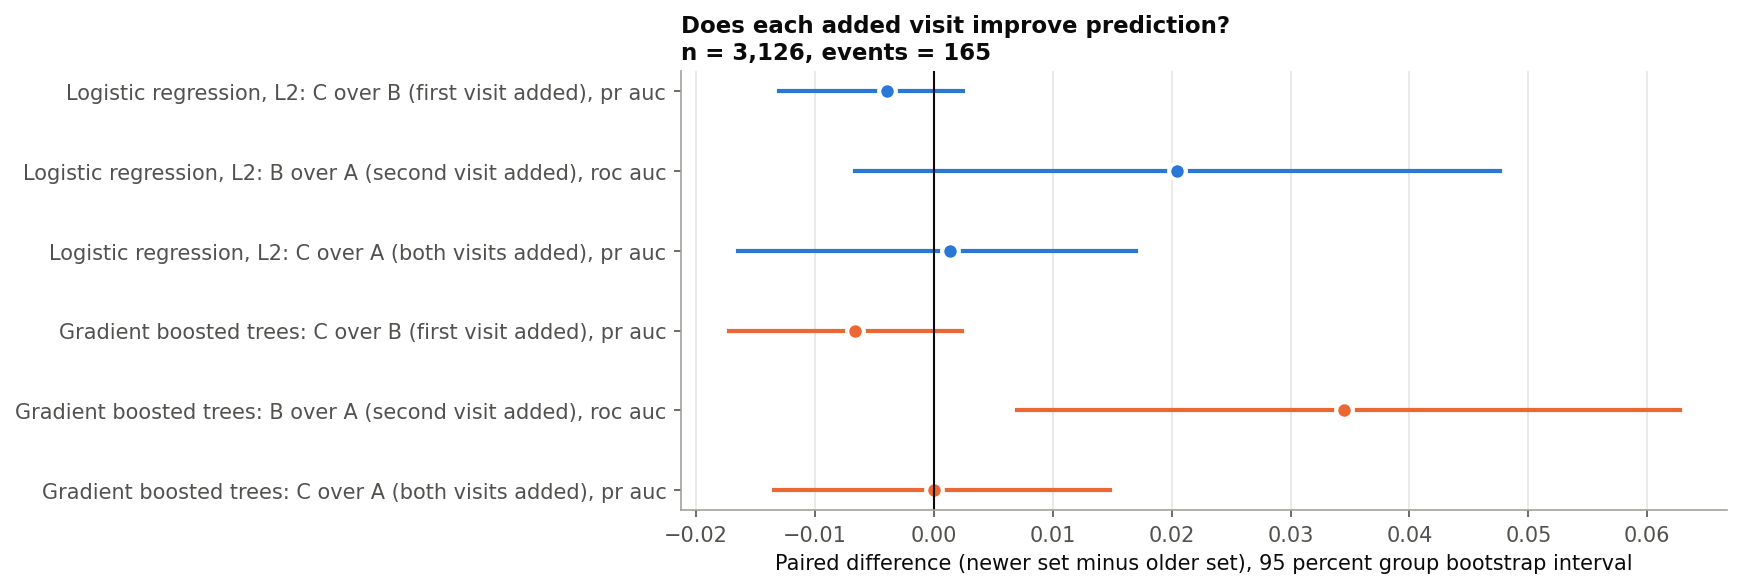

In [7]:
comparisons = table("feature_set_comparisons")
tested = comparisons[comparisons["role"] != "descriptive"]
display(tested[["model", "comparison", "metric", "role", "new_value", "old_value", "difference", "ci_low", "ci_high", "detectable_difference"]])
figure("fig07_feature_set_differences")

In [8]:
def verdict(row):
    if row.ci_low > 0:
        return "a gain whose interval excludes zero"
    if row.ci_high < 0:
        return "a loss whose interval excludes zero"
    return "no difference distinguishable from zero"

for row in tested[tested["role"].isin(["primary", "secondary"])].itertuples():
    print(f"{MODEL_SPECS[row.model].label}, {row.comparison} on {row.metric.replace('_', ' ')}: "
          f"{row.difference:+.4f} (95 percent interval {row.ci_low:+.4f} to {row.ci_high:+.4f}); "
          f"{verdict(row)}. Smallest difference this design could detect: {row.detectable_difference:.4f}.")

Logistic regression, L2, C over B (first visit added) on pr auc: -0.0040 (95 percent interval -0.0130 to +0.0025); no difference distinguishable from zero. Smallest difference this design could detect: 0.0110.
Logistic regression, L2, B over A (second visit added) on roc auc: +0.0205 (95 percent interval -0.0066 to +0.0476); no difference distinguishable from zero. Smallest difference this design could detect: 0.0385.
Gradient boosted trees, C over B (first visit added) on pr auc: -0.0066 (95 percent interval -0.0173 to +0.0024); no difference distinguishable from zero. Smallest difference this design could detect: 0.0144.
Gradient boosted trees, B over A (second visit added) on roc auc: +0.0345 (95 percent interval +0.0070 to +0.0627); a gain whose interval excludes zero. Smallest difference this design could detect: 0.0397.


## 7. How large a difference could this study detect?

A null result means something only when it says how large a difference the study could have seen. The detectable difference is 2.8 bootstrap standard errors, the size a two sided test at the 5 percent level would detect four times in five.

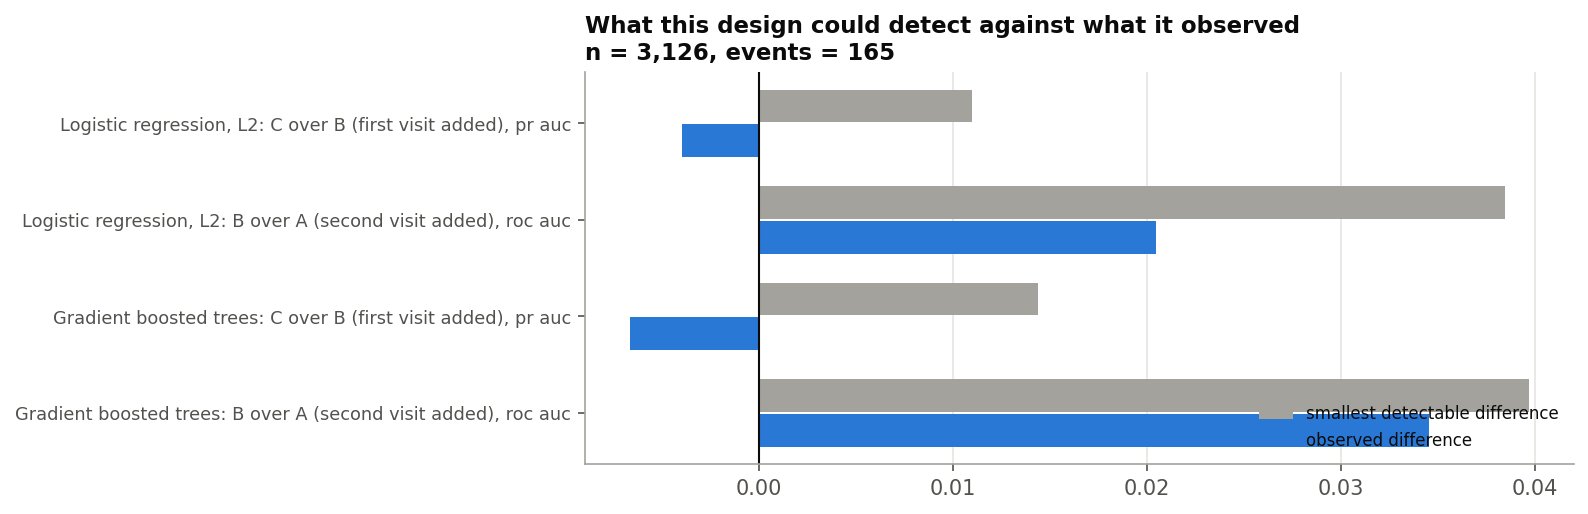

,model,comparison,metric,role,difference,bootstrap_se,detectable_difference
0,logistic_l2,C over B (first visit added),pr_auc,primary,-3.9599e-03,0.0039,0.0110
1,logistic_l2,B over A (second visit added),roc_auc,secondary,2.0487e-02,0.0137,0.0385
2,logistic_l2,C over A (both visits added),pr_auc,supporting,1.3560e-03,0.0085,0.0237
3,logistic_l2,A over B0 (registration over prevalence),pr_auc,supporting,3.3796e-02,0.0119,0.0333
4,logistic_l2,B over B0,pr_auc,supporting,3.9112e-02,0.0123,0.0346
5,logistic_l2,C over B0,pr_auc,supporting,3.5152e-02,0.0114,0.0320
6,gradient_boosting,C over B (first visit added),pr_auc,primary,-6.6325e-03,0.0051,0.0144
7,gradient_boosting,B over A (second visit added),roc_auc,secondary,3.4536e-02,0.0142,0.0397
8,gradient_boosting,C over A (both visits added),pr_auc,supporting,3.3639e-06,0.0072,0.0202
9,gradient_boosting,A over B0 (registration over prevalence),pr_auc,supporting,3.3449e-02,0.0110,0.0309


In [9]:
figure("fig10_detectable_difference")
display(table("detectable_difference"))

## 8. Can the probabilities be taken at face value?

Calibration compares predicted risk with observed rates in groups of equal size. Points on the diagonal mean a predicted 6 percent really happens about 6 times in 100. The slope says whether predictions are too spread out (below one) or too compressed (above one).

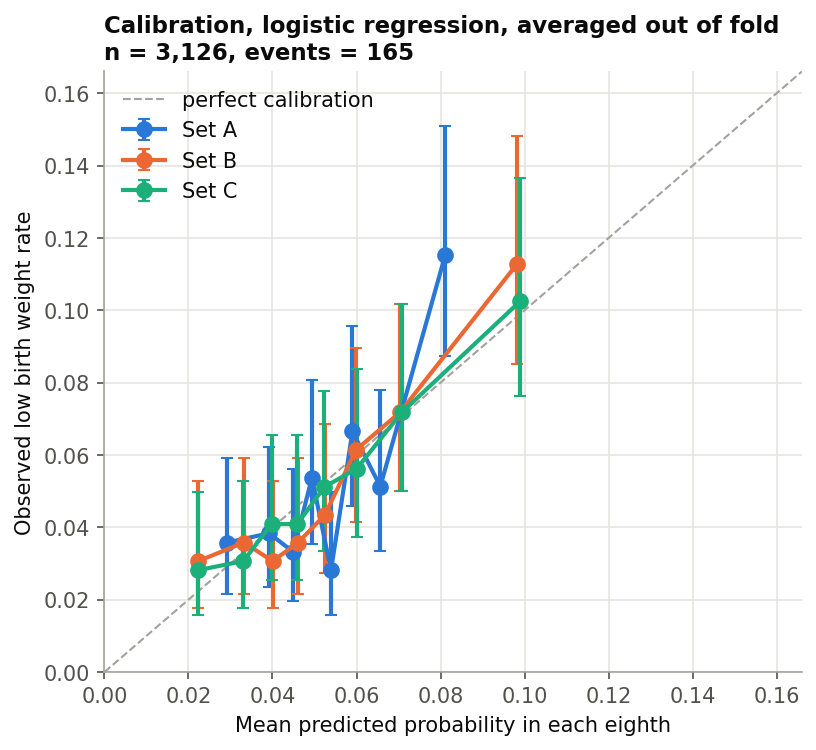

,feature_set,pr_auc,roc_auc,brier,calibration_slope,calibration_intercept
11,A,0.0880,0.6113,0.0496,1.2090,-0.0002
12,B,0.0933,0.6318,0.0494,1.0114,-0.0005
13,C,0.0894,0.6281,0.0494,0.9788,-0.0018


In [10]:
figure("fig08_calibration")
summary = table("summary_by_experiment")
display(summary[summary["model"] == "logistic_l2"][["feature_set", "pr_auc", "roc_auc", "brier", "calibration_slope", "calibration_intercept"]])

## 9. Would acting on the model do more good than simple policies?

Net benefit counts the low birth weight pregnancies found minus the false alarms, weighted by how much a false alarm is tolerated at each threshold. A model is useful at a threshold only when its curve lies above both "act for everyone" and "act for no one". This describes retrospective ranking only and makes no claim that earlier contact would change any outcome.

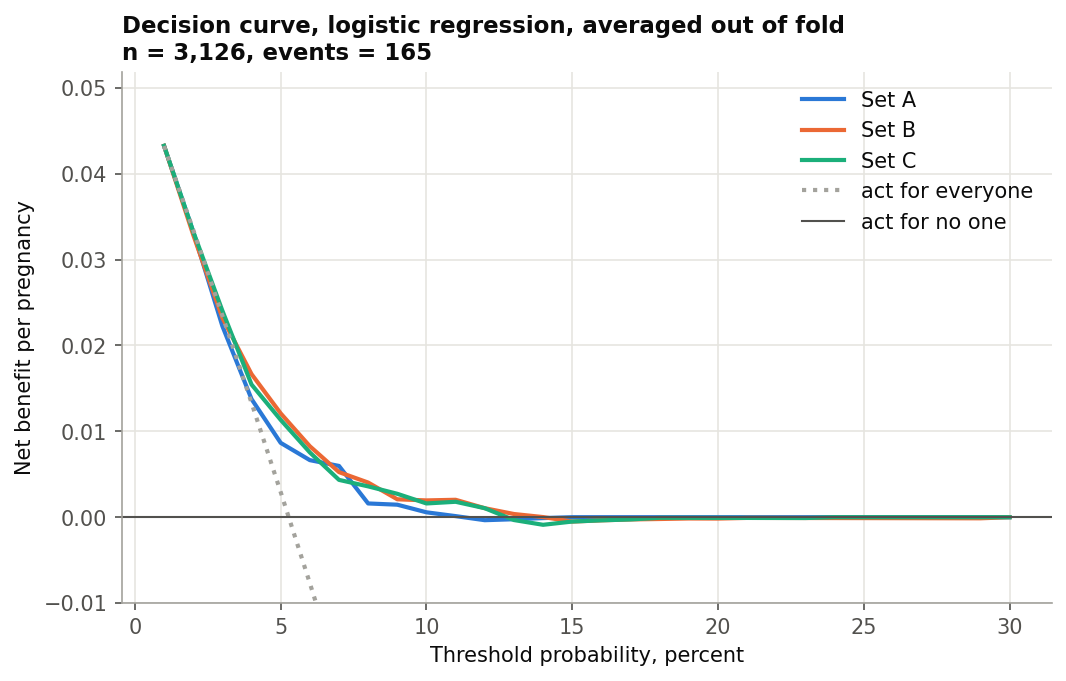

,rule,n,events,flagged,events_flagged,sensitivity,positive_predictive_value
0,Visit two blood pressure at or above 140/90,3126,165,34,5,0.0303,0.1471


In [11]:
figure("fig09_decision_curve")
display(table("clinical_rule_b3"))

The second table is baseline B3, a descriptive clinical rule: a visit two blood pressure of 140/90 or above. It targets hypertensive disorders, not birth weight, so it is shown for context and not tested.

## 10. Sensitivity analyses

The primary comparison is repeated under each pre specified change to the cohort or the features. Variant cohorts drop every record in the sealed held out partition, so it stays unseen.

,analysis,specification,comparison,metric,difference,ci_low,ci_high,n,events
0,S1,Visit two by 24 weeks,C over B,pr_auc,-0.0035,-0.0116,0.0036,1945,113
3,S1,Visit two by 24 weeks,B over A,roc_auc,0.0063,-0.0214,0.0320,1945,113
4,S2,Visit two by 32 weeks,C over B,pr_auc,-0.0033,-0.0130,0.0052,4301,199
7,S2,Visit two by 32 weeks,B over A,roc_auc,0.0266,0.0031,0.0514,4301,199
8,S3,Excluding records marked both term and preterm,C over B,pr_auc,-0.0023,-0.0114,0.0042,3079,162
11,S3,Excluding records marked both term and preterm,B over A,roc_auc,0.0206,-0.0061,0.0465,3079,162
12,S4,Every screened measurement recorded at both vi...,C over B,pr_auc,-0.0010,-0.0067,0.0046,2504,144
15,S4,Every screened measurement recorded at both vi...,B over A,roc_auc,0.0129,-0.0088,0.0343,2504,144
16,S5,Rate of change per week added to set C,C_rate_per_week over B,pr_auc,-0.0057,-0.0162,0.0006,3126,165
19,S5,Rate of change per week added to set C,B over A,roc_auc,0.0205,-0.0066,0.0476,3126,165


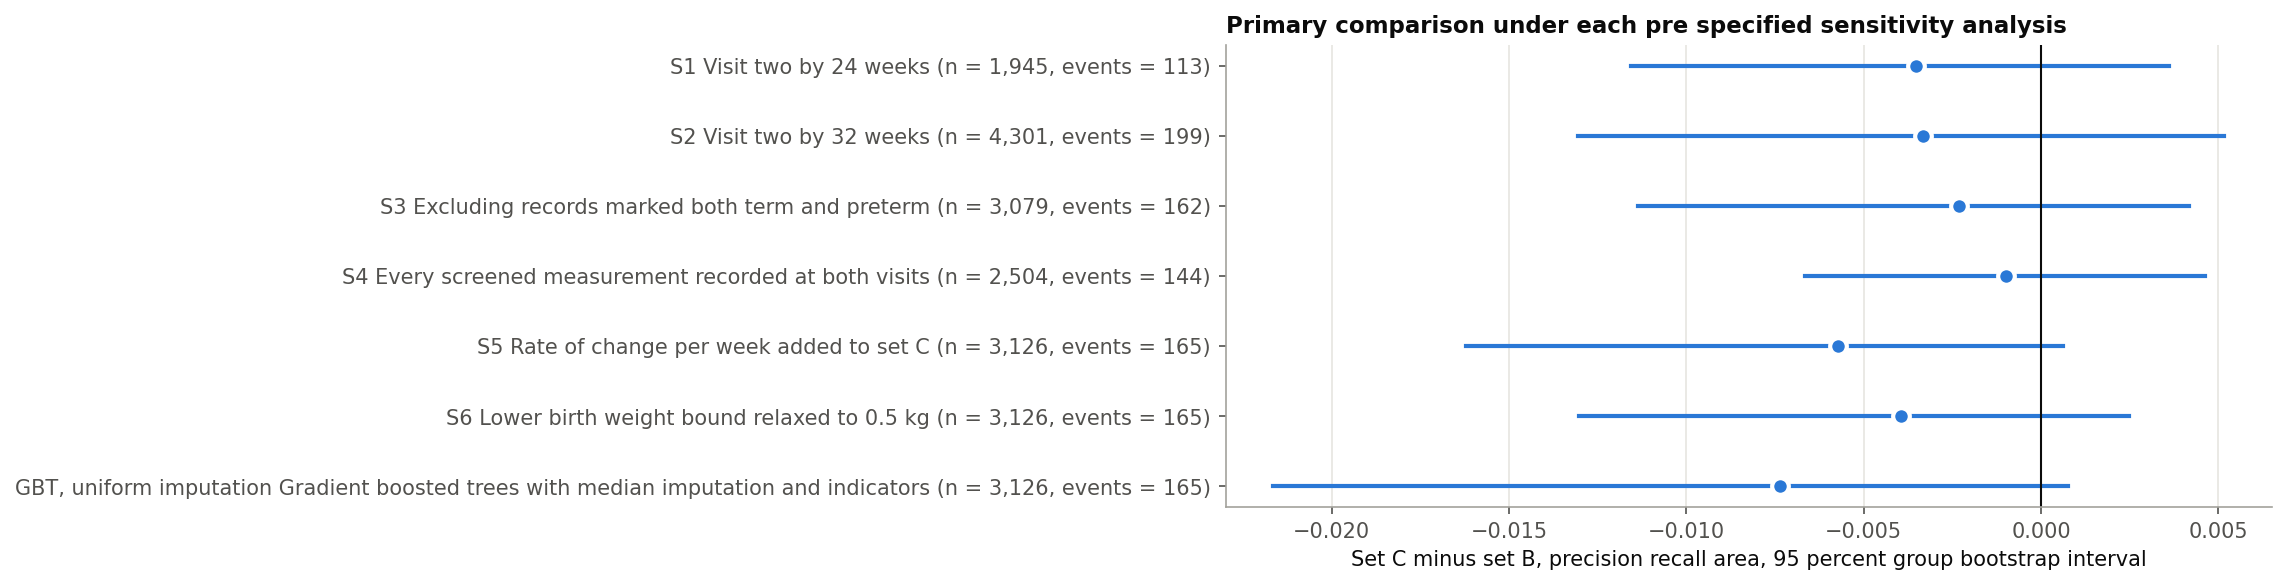

In [12]:
sensitivity = table("sensitivity_analyses")
display(sensitivity[sensitivity["role"] != "descriptive"][["analysis", "specification", "comparison", "metric", "difference", "ci_low", "ci_high", "n", "events"]])
figure("fig11_sensitivity")

## Further analyses on development records

The analyses below extend the primary comparison. All of them use development records only, the same sealed folds, and predictions paired with the primary results. They are written by `python -m antenatal run-extensions`.

### Is the null result limited by the amount of data?

Each outer training fold is cut to 20, 40, 60, 80 and 100 percent of its registration groups, and the model is fitted exactly as in the primary design. If set C began to pull away from set B as the data grew, more data might reveal a difference. If the gap stays flat, it probably would not.

,fraction,n_train,events_train,pr_auc_gap_mean,pr_auc_gap_std,roc_auc_gap_mean,roc_auc_gap_std
1,0.2,500.20,26.94,-0.0014,0.0051,-0.0056,0.0136
3,0.4,1000.48,52.36,-0.0011,0.0045,0.0005,0.0128
5,0.6,1500.62,78.66,-0.0039,0.0063,-0.0032,0.0067
7,0.8,2001.02,105.54,-0.0020,0.0046,-0.0035,0.0064
9,1.0,2500.80,132.00,-0.0041,0.0049,-0.0040,0.0041


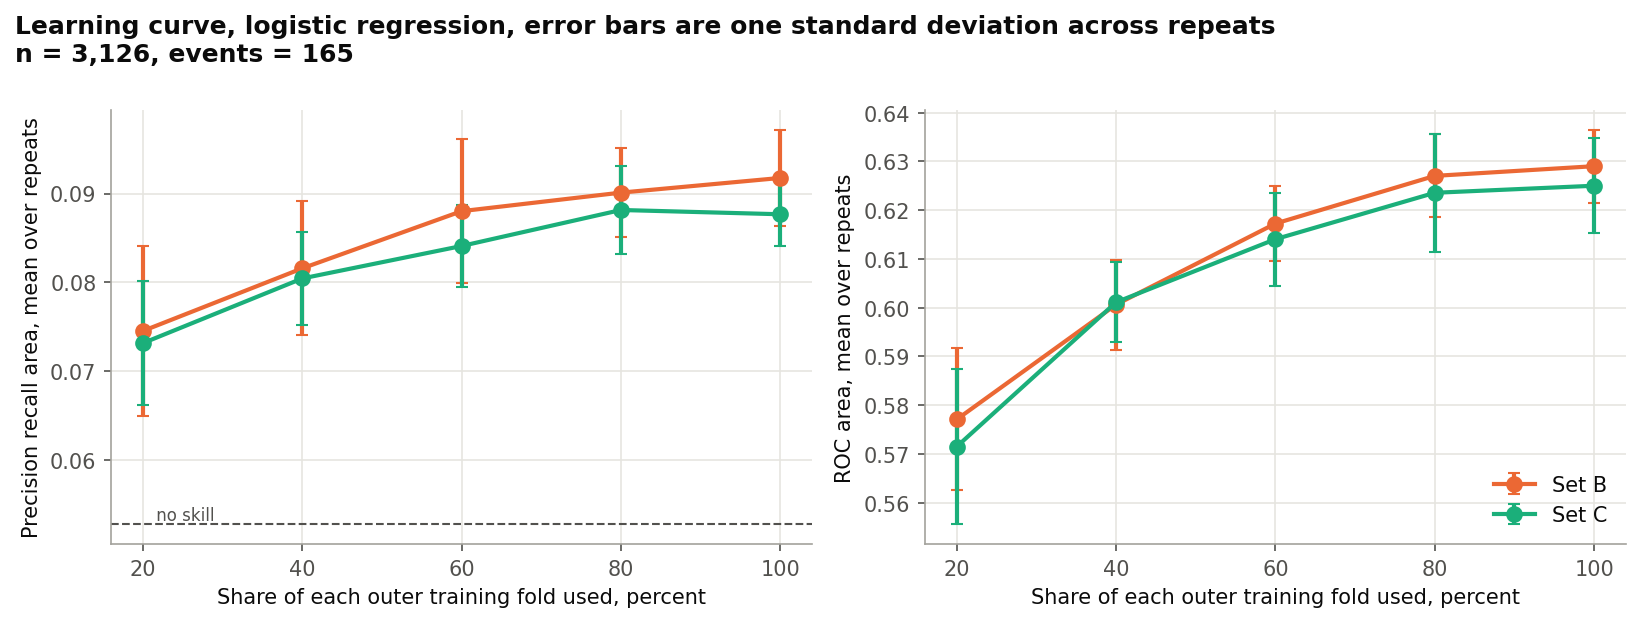

In [13]:
curve = table("learning_curve")
display(curve[curve["feature_set"] == "C"][["fraction", "n_train", "events_train", "pr_auc_gap_mean", "pr_auc_gap_std", "roc_auc_gap_mean", "roc_auc_gap_std"]])
figure("fig12_learning_curve")

### Which first visit measurement carries the signal, if any?

Each visit one measurement is removed from set C in turn. A positive difference means the full set C does better with that measurement kept.

,comparison,metric,difference,ci_low,ci_high
0,Visit one sbp kept,pr_auc,-0.0008,-0.0053,0.0023
1,Visit one sbp kept,roc_auc,0.0023,-0.0028,0.0076
2,Visit one dbp kept,pr_auc,-0.0003,-0.0020,0.0016
3,Visit one dbp kept,roc_auc,-0.0013,-0.0032,0.0008
4,Visit one weight kept,pr_auc,0.0004,-0.0045,0.0037
5,Visit one weight kept,roc_auc,0.0006,-0.0029,0.0044
6,Visit one ga kept,pr_auc,0.0003,-0.0026,0.0033
7,Visit one ga kept,roc_auc,-0.0020,-0.0066,0.0021
8,Visit one pulse kept,pr_auc,-0.0016,-0.0082,0.0032
9,Visit one pulse kept,roc_auc,0.0018,-0.0059,0.0097


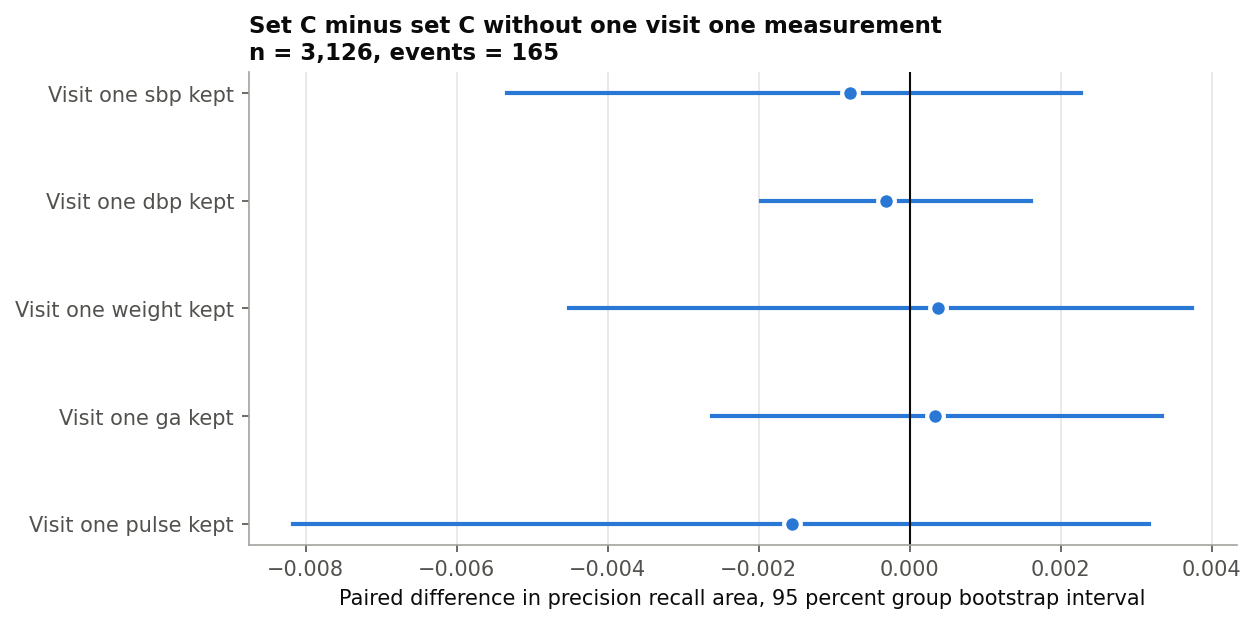

In [14]:
ablation = table("ablation")
display(ablation[["comparison", "metric", "difference", "ci_low", "ci_high"]])
figure("fig13_ablation")

### Does the way the first visit is entered matter?

Four pre specified ways of entering the first visit are compared on the same folds: the values themselves (primary), values plus the change, the change only, and the change per week (S5).

,comparison,new_value,difference,ci_low,ci_high
0,C over B,0.0894,-0.0040,-0.0130,0.0025
2,C_values_and_change over B,0.0890,-0.0043,-0.0142,0.0042
4,C_change_only over B,0.0906,-0.0027,-0.0105,0.0071
6,C_rate_per_week over B,0.0876,-0.0057,-0.0162,0.0006
8,C_values_and_change over C,0.0890,-0.0004,-0.0045,0.0076
10,C_change_only over C,0.0906,0.0012,-0.0037,0.0125
12,C_rate_per_week over C,0.0876,-0.0018,-0.0070,0.0022


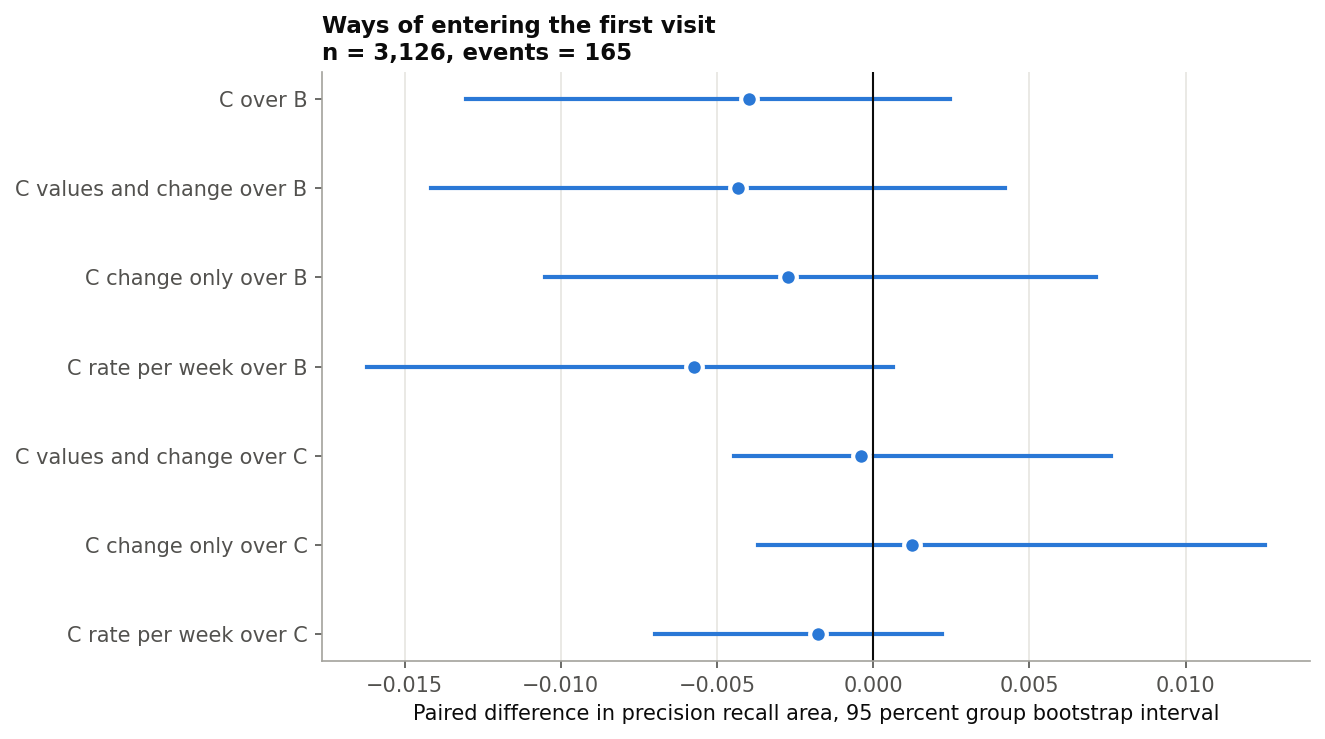

In [15]:
param = table("parameterisation")
display(param[param["metric"] == "pr_auc"][["comparison", "new_value", "difference", "ci_low", "ci_high"]])
figure("fig14_parameterisation")

### Is missingness informative?

Two questions. First, does the low birth weight rate differ between pregnancies with and without a visit two value? Second, do the missingness indicators, which the pipeline adds for every imputed measurement, improve prediction in sets B and C when compared with the same model without them?

,measurement,recorded_n,recorded_rate,recorded_low,recorded_high,missing_n,missing_rate,missing_low,missing_high,difference_missing_minus_recorded,difference_low,difference_high,note
0,Systolic blood pressure,3126,0.0528,0.0455,0.0612,0,NaN,NaN,NaN,NaN,NaN,NaN,Recorded for every record by the cohort rule
1,Diastolic blood pressure,3126,0.0528,0.0455,0.0612,0,NaN,NaN,NaN,NaN,NaN,NaN,Recorded for every record by the cohort rule
2,Weight,3116,0.0530,0.0456,0.0614,10,0.0000,0.0000,0.2775,-0.0530,-0.0614,0.2247,NaN
3,Gestational week,3126,0.0528,0.0455,0.0612,0,NaN,NaN,NaN,NaN,NaN,NaN,Recorded for every record by the cohort rule
4,Pulse rate,2544,0.0574,0.0490,0.0671,582,0.0326,0.0210,0.0504,-0.0247,-0.0399,-0.0051,NaN
5,Haemoglobin,1213,0.0503,0.0393,0.0641,1913,0.0544,0.0451,0.0654,0.0041,-0.0125,0.0196,NaN


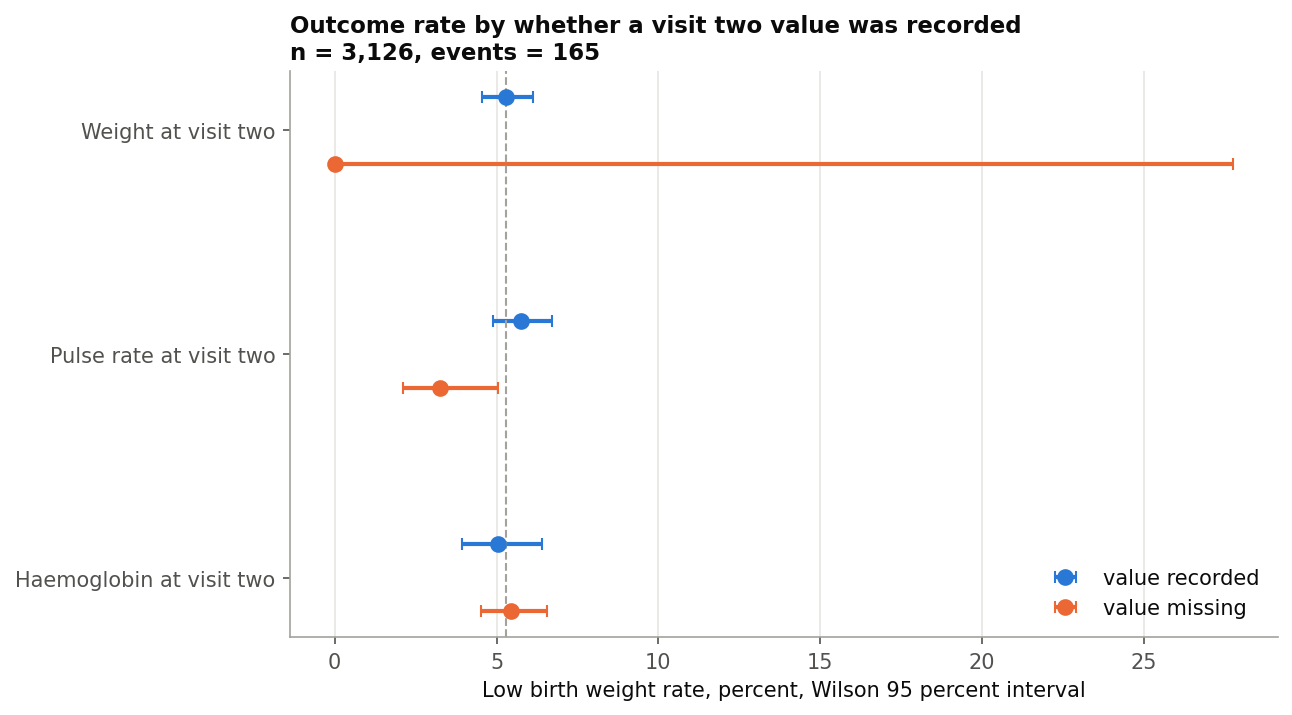

,comparison,metric,difference,ci_low,ci_high
0,"Indicators added, set B",pr_auc,0.0029,-0.0088,0.0147
1,"Indicators added, set B",roc_auc,0.0085,-0.0079,0.0232
2,"Indicators added, set C",pr_auc,0.0022,-0.0069,0.0114
3,"Indicators added, set C",roc_auc,0.0084,-0.0069,0.0224


In [16]:
rates = table("missingness_outcome_rates")
display(rates[["measurement", "recorded_n", "recorded_rate", "recorded_low", "recorded_high", "missing_n", "missing_rate", "missing_low", "missing_high", "difference_missing_minus_recorded", "difference_low", "difference_high", "note"]])
figure("fig15_missingness_rates")
signal = table("missingness_indicator_signal")
display(signal[["comparison", "metric", "difference", "ci_low", "ci_high"]])

In [17]:
for row in rates[rates["missing_n"] > 0].itertuples():
    excludes = row.difference_high < 0 or row.difference_low > 0
    print(f"{row.measurement}: {100 * row.missing_rate:.1f} percent low birth weight when missing ({row.missing_n} records) "
          f"against {100 * row.recorded_rate:.1f} percent when recorded; difference {100 * row.difference_missing_minus_recorded:+.1f} "
          f"points ({100 * row.difference_low:+.1f} to {100 * row.difference_high:+.1f}), "
          + ("interval excludes zero." if excludes else "interval includes zero."))
for row in signal[signal["metric"] == "pr_auc"].itertuples():
    print(f"{row.comparison}: {row.difference:+.4f} ({row.ci_low:+.4f} to {row.ci_high:+.4f}) in precision recall area.")

Weight: 0.0 percent low birth weight when missing (10 records) against 5.3 percent when recorded; difference -5.3 points (-6.1 to +22.5), interval includes zero.
Pulse rate: 3.3 percent low birth weight when missing (582 records) against 5.7 percent when recorded; difference -2.5 points (-4.0 to -0.5), interval excludes zero.
Haemoglobin: 5.4 percent low birth weight when missing (1913 records) against 5.0 percent when recorded; difference +0.4 points (-1.3 to +2.0), interval includes zero.
Indicators added, set B: +0.0029 (-0.0088 to +0.0147) in precision recall area.
Indicators added, set C: +0.0022 (-0.0069 to +0.0114) in precision recall area.


**Interpretation, read with caution.** Systolic and diastolic pressure and gestational week are never missing here, because the cohort rule requires them, and weight is missing for very few records. The informative rows are pulse and haemoglobin. Pregnancies without a recorded visit two pulse had a lower recorded low birth weight rate than those with one. This should be read as a fact about **recording practice, not physiology**. A pulse is skipped or recorded depending on the clinic, the day and the worker, and clinics may also differ in who they serve and how they weigh newborns. The file has no facility identifier, so the two cannot be separated. The same comparison for haemoglobin shows no clear difference. Adding the missingness indicators to the model gives no gain that can be told apart from zero in either set B or set C, so whatever association exists does not translate into usable predictive signal at this sample size. None of this suggests that measuring or not measuring pulse changes birth weight.

### Does the way the trees handle missing values matter?

The gradient boosted trees handle missing values natively, as the proposal states. The same trees with median imputation and indicators are compared on the same folds.

In [18]:
gbt = table("gbt_missing_value_handling")
display(gbt[gbt["role"] != "descriptive"][["model", "comparison", "metric", "role", "difference", "ci_low", "ci_high"]])

,model,comparison,metric,role,difference,ci_low,ci_high
0,gradient_boosting,"Native over uniform, set A",pr_auc,extension,0.0036,-0.0042,0.0121
2,gradient_boosting,"Native over uniform, set B",pr_auc,extension,0.0008,-0.0074,0.0084
4,gradient_boosting,"Native over uniform, set C",pr_auc,extension,0.0015,-0.0034,0.0108
6,gradient_boosting,C over B,pr_auc,primary,-0.0066,-0.0173,0.0024
9,gradient_boosting,B over A,roc_auc,secondary,0.0345,0.0070,0.0627
10,gradient_boosting_uniform,C over B,pr_auc,primary,-0.0074,-0.0216,0.0008
13,gradient_boosting_uniform,B over A,roc_auc,secondary,0.0431,0.0151,0.0727


### Does the result depend on median imputation?

The primary comparison is repeated with iterative imputation drawn five times from its posterior. The five sets of predictions are averaged per pregnancy before the paired bootstrap, and each draw is also shown on its own.

In [19]:
mi = table("multiple_imputation")
display(mi[mi["metric"] == "pr_auc"][["model", "new_value", "old_value", "difference", "ci_low", "ci_high"]])

,model,new_value,old_value,difference,ci_low,ci_high
0,logistic_l2,0.0894,0.0933,-0.0040,-0.0130,0.0025
2,logistic_l2_iterative_pooled,0.0927,0.0982,-0.0055,-0.0151,0.0008
4,logistic_l2_iterative_0,0.0916,0.0976,-0.0060,-0.0159,0.0013
6,logistic_l2_iterative_1,0.0937,0.1009,-0.0071,-0.0214,0.0013
8,logistic_l2_iterative_2,0.0942,0.0977,-0.0035,-0.0136,0.0034
10,logistic_l2_iterative_3,0.0903,0.0954,-0.0051,-0.0157,0.0046
12,logistic_l2_iterative_4,0.0939,0.0982,-0.0043,-0.0157,0.0030


### Subgroups

Performance is reported for an age band or parity group only when it holds at least 30 events. Parity comes from the recorded prior deliveries, which the data audit found unreliable, so the parity rows carry that caution.

In [20]:
display(table("subgroups"))

,stratum,n,events,reported,reason,metric,prevalence,set_c,set_c_low,set_c_high,c_minus_b,c_minus_b_low,c_minus_b_high
0,Age under 20,513,46,True,NaN,pr_auc,0.0897,0.1197,0.0832,0.1823,-0.0068,-0.0329,0.0079
1,Age under 20,513,46,True,NaN,roc_auc,0.0897,0.6038,0.5254,0.6812,-0.0135,-0.0395,0.0118
2,Age 20 to 34,2171,94,True,NaN,pr_auc,0.0433,0.0805,0.0569,0.1225,-0.0020,-0.0161,0.0081
3,Age 20 to 34,2171,94,True,NaN,roc_auc,0.0433,0.6183,0.5554,0.6793,-0.0044,-0.0182,0.0102
4,Age 35 or over,388,22,False,Fewer than 30 events,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Age missing,54,3,False,Fewer than 30 events,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,No prior delivery,142,11,False,Fewer than 30 events,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,One or more prior deliveries,2984,154,True,NaN,pr_auc,0.0516,0.0906,0.0698,0.1209,-0.0037,-0.0129,0.0028
8,One or more prior deliveries,2984,154,True,NaN,roc_auc,0.0516,0.6334,0.5870,0.6785,-0.0021,-0.0118,0.0080


### Question 3: retrieval within fixed ranking budgets

How many low birth weight births would sit in the top 10, 20 or 30 percent of a ranking by the primary model, compared with ranking at random? This describes retrospective ranking only. It does not show that earlier or more frequent contact would change any outcome.

,model,budget_percent,pregnancies_in_budget,events_found,events_total,retrieval,ci_low,ci_high,random_expectation,ratio_to_random,n
0,"logistic_l2, set C",10,313,36,165,0.2182,0.1585,0.2792,0.1,2.1818,3126
1,"logistic_l2, set C",20,626,57,165,0.3455,0.2781,0.4204,0.2,1.7273,3126
2,"logistic_l2, set C",30,938,79,165,0.4788,0.4041,0.5537,0.3,1.5960,3126


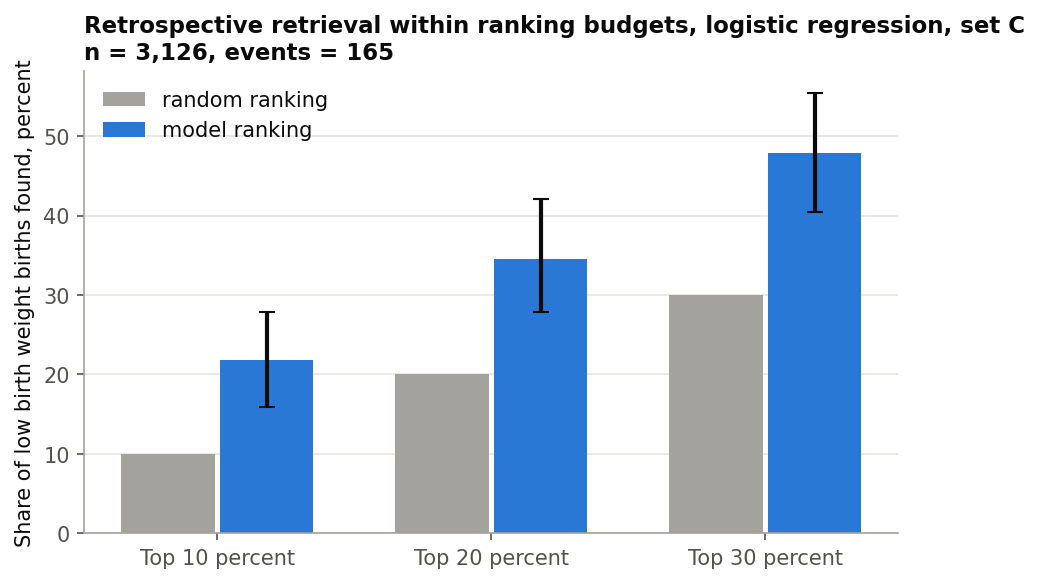

In [21]:
display(table("retrieval_at_budget"))
figure("fig16_retrieval_at_budget")

### Question 2: calibration of each set

Calibration slope and intercept for sets A, B and C, for both model families, with group bootstrap intervals. Read with the discrimination results above, this answers whether adding the earlier visit improves calibration as well as discrimination.

In [22]:
display(table("calibration_by_set"))

,model,feature_set,n,events,calibration_slope,calibration_slope_low,calibration_slope_high,calibration_intercept,calibration_intercept_low,calibration_intercept_high
0,logistic_l2,A,3126,165,1.2090,0.6443,1.8227,-0.0002,-0.1687,0.1536
1,logistic_l2,B,3126,165,1.0114,0.6386,1.4147,-0.0005,-0.1677,0.1516
2,logistic_l2,C,3126,165,0.9788,0.6266,1.3677,-0.0018,-0.1675,0.1504
3,gradient_boosting,A,3126,165,0.9200,0.6142,1.2522,-0.0064,-0.1731,0.1465
4,gradient_boosting,B,3126,165,1.1438,0.8029,1.4769,0.0013,-0.1640,0.1545
5,gradient_boosting,C,3126,165,1.1613,0.7911,1.5293,0.0032,-0.1616,0.1556


## 11. The frozen artefact

The configuration served by the prototype was fixed before results were read: L2 logistic regression on set C, because set C is the set the question is about and the interval on an individual probability needs the coefficient covariance of a linear model. It is fitted once on the development records and saved with a SHA 256 and a version record. The coefficients below describe how the model behaves. They are not clinical explanations of low birth weight.

In [23]:
version = json.loads((paths.model / "version.json").read_text())
display(pd.Series(version).to_frame("value"))
params = json.loads((paths.model / "model_params.json").read_text())
names = params["feature_names"] + [f"{name} missing" for name in params["indicator_features"]]
weights = pd.DataFrame({"feature": names, "standardised_weight": params["coefficients"]})
display(weights.reindex(weights["standardised_weight"].abs().sort_values(ascending=False).index).head(10))

,value
version,1.0.0
created_at,2026-10-21T15:39:33+00:00
artefact_sha256,7358b0b26f83aa6072f55986652d8691f111dbc6646a31...
data_sha256,ab95366ef22dde5d13df93f10723942f5faffda8fbf000...
partition_sha256,249114c363dab8a86c5acbee9bb8cfd6fddbf97b3d74b6...
seed,20260930
family,logistic_l2
feature_set,C
n_features,25
n_development,3126


,feature,standardised_weight
3,height_cm,-0.1580
4,registration_weight,-0.1467
29,pulse_v2 missing,-0.0966
14,sbp_v2,0.0958
0,age,-0.0890
22,weight_v1,-0.0844
16,weight_v2,-0.0833
24,pulse_v1,0.0737
1,gravidity,-0.0721
27,registration_weight missing,0.0696


## 12. Limitations

* One public Tanzanian dataset with no geographic identifier, so neither external nor geographic validation is possible.
* 165 development events give few events per candidate predictor, so only differences of roughly the detectable size above could be seen.
* Haemoglobin is recorded at visit two for a minority of pregnancies, so the test of the earlier visit rests mainly on blood pressure, weight, gestational week and pulse.
* The outcome is the recorded birth weight under the care actually given. The model estimates that recorded outcome, and nothing here shows that acting on a prediction would change it.
* The prototype uses synthetic cases only and is not validated for any real pregnancy.

## References

Collins, G. S., et al. (2024). TRIPOD+AI statement. BMJ, 385, e078378.
Davis, J., and Goadrich, M. (2006). The relationship between precision recall and ROC curves. ICML, 233 to 240.
Mwifunyi, R., et al. (2025). Dataset for maternal health risks stratification (MHRS) in Tanzania (Version 1). Zenodo. https://doi.org/10.5281/zenodo.15309733
Nadeau, C., and Bengio, Y. (2003). Inference for the generalization error. Machine Learning, 52, 239 to 281.
Saito, T., and Rehmsmeier, M. (2015). The precision recall plot is more informative than the ROC plot. PLOS ONE, 10(3), e0118432.
Van Calster, B., et al. (2019). Calibration: the Achilles heel of predictive analytics. BMC Medicine, 17, 230.
van den Goorbergh, R., et al. (2022). The harm of class imbalance corrections for risk prediction models. JAMIA, 29(9), 1525 to 1534.
Vickers, A. J., and Elkin, E. B. (2006). Decision curve analysis. Medical Decision Making, 26(6), 565 to 574.